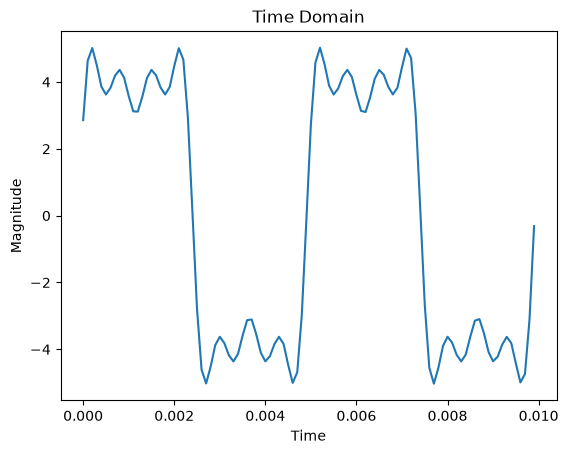

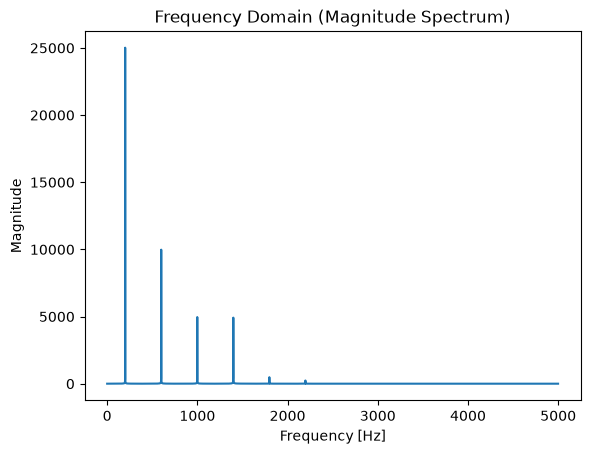

In [3]:
#
#
#
import numpy as np
import matplotlib.pyplot as plt
import arslabrobotics as ar

delta_t = 1e-4  # Sampling interval
freq = 200
a = [ 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0 ]
b = [ 5, 0, 2, 0, 1, 0, 1, 0, 0.1, 0, 0.05, 0 ]

signal = []

# generate a signal using Fourier series
tm = ar.utils.Time(use_fake_time = True)
tm.start()
while tm.get() < 1:
    tm.sleep(delta_t)
    tm.elapsed()
    val = a[0] / 2
    t = tm.get()
    for i in range(len(b)):
        val += a[i+1] * np.cos(2 * np.pi * freq * (i+1) * t) + b[i] * np.sin(2 * np.pi * freq * (i+1) * t)
    signal.append(val)

# Compute FFT
fft_values = np.fft.fft(signal)
N = len(signal)

# Compute frequency bins
freq = np.fft.fftfreq(N, delta_t)

# Take the magnitude (absolute value) of the FFT
magnitude = np.abs(fft_values)

n_samples = 100
plt.plot(np.arange(n_samples) * delta_t, signal[:n_samples])
plt.title('Time Domain')
plt.xlabel('Time')
plt.ylabel('Magnitude')
plt.show()

n_samples = N//2
plt.plot(freq[:n_samples], magnitude[:n_samples])
plt.title('Frequency Domain (Magnitude Spectrum)')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Magnitude')
plt.show()